In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
import tensorflow as tf

import random
from PIL import Image

In [2]:
for root, dirs, files in os.walk('/kaggle/input'):
    level = root.replace('/kaggle/input', '').count(os.sep)

    if level <= 3:
        print(root)
        print("Folders:", dirs[:10])
        print("Images/files:", len(files))
        print("-" * 40)

/kaggle/input
Folders: ['datasets']
Images/files: 0
----------------------------------------
/kaggle/input/datasets
Folders: ['mosabbirahmed']
Images/files: 0
----------------------------------------
/kaggle/input/datasets/mosabbirahmed
Folders: ['intel-image-classification-no-splits']
Images/files: 0
----------------------------------------
/kaggle/input/datasets/mosabbirahmed/intel-image-classification-no-splits
Folders: ['intel_dataset']
Images/files: 0
----------------------------------------


In [3]:
data_dir='/kaggle/input/datasets/mosabbirahmed/intel-image-classification-no-splits/intel_dataset'

for item in sorted(os.listdir(data_dir)):
    path=os.path.join(data_dir,item)

    if os.path.isdir(path):
        print(f'Folder: {item}')
        print('Number of items:', len(os.listdir(path)))
        print('Sample items:', os.listdir(path)[:5])
        print('-' * 40)
    else:
        print(f'File: {item}')

Folder: buildings
Number of items: 2609
Sample items: ['22735.jpg', '22706.jpg', '2193.jpg', '11378.jpg', '10730.jpg']
----------------------------------------
Folder: forest
Number of items: 2745
Sample items: ['7981.jpg', '3863.jpg', '11925.jpg', '23407.jpg', '10597.jpg']
----------------------------------------
Folder: glacier
Number of items: 2874
Sample items: ['12666.jpg', '13288.jpg', '3750.jpg', '6588.jpg', '7966.jpg']
----------------------------------------
Folder: mountain
Number of items: 3027
Sample items: ['22608.jpg', '14986.jpg', '3138.jpg', '1700.jpg', '16257.jpg']
----------------------------------------
Folder: sea
Number of items: 2762
Sample items: ['19812.jpg', '16916.jpg', '20513.jpg', '10304.jpg', '623.jpg']
----------------------------------------
Folder: street
Number of items: 2883
Sample items: ['20088.jpg', '1269.jpg', '6241.jpg', '14143.jpg', '2008.jpg']
----------------------------------------


In [4]:
#from collections import Counter
classes=sorted([
    name for name in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir,name))
])
print('calsses: ',classes)

image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

counts = {}

for class_name in classes:
    class_path=os.path.join(data_dir,class_name)

    images=[
      f for f in os.listdir(class_path)
      if f.lower().endswith(image_extensions)
    and os.path.isfile(os.path.join(class_path,f))
  ]
    counts[class_name]=len(images)

print("\nNumber of images per class:")
for name, count in counts.items():
    print(f"{name}: {count}")

print("\nTotal images:", sum(counts.values()))



calsses:  ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

Number of images per class:
buildings: 2609
forest: 2745
glacier: 2874
mountain: 3027
sea: 2762
street: 2883

Total images: 16900


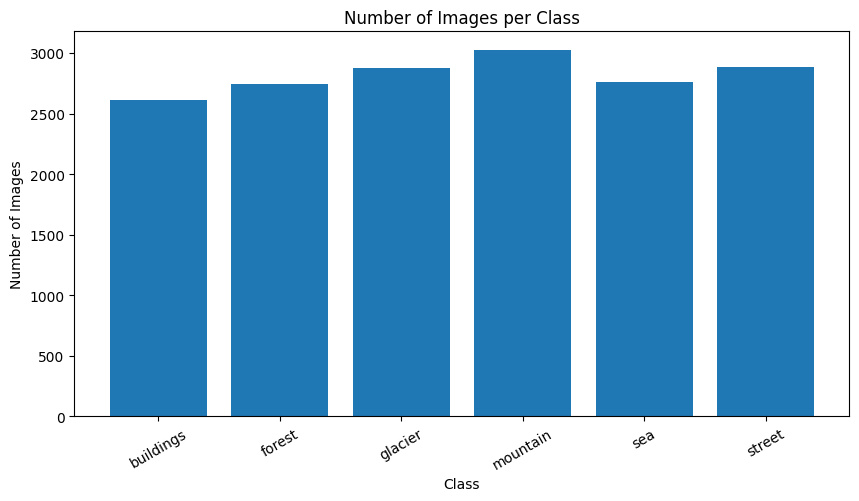

In [5]:
plt.figure(figsize=(10, 5))

plt.bar(counts.keys(), counts.values())
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.show()

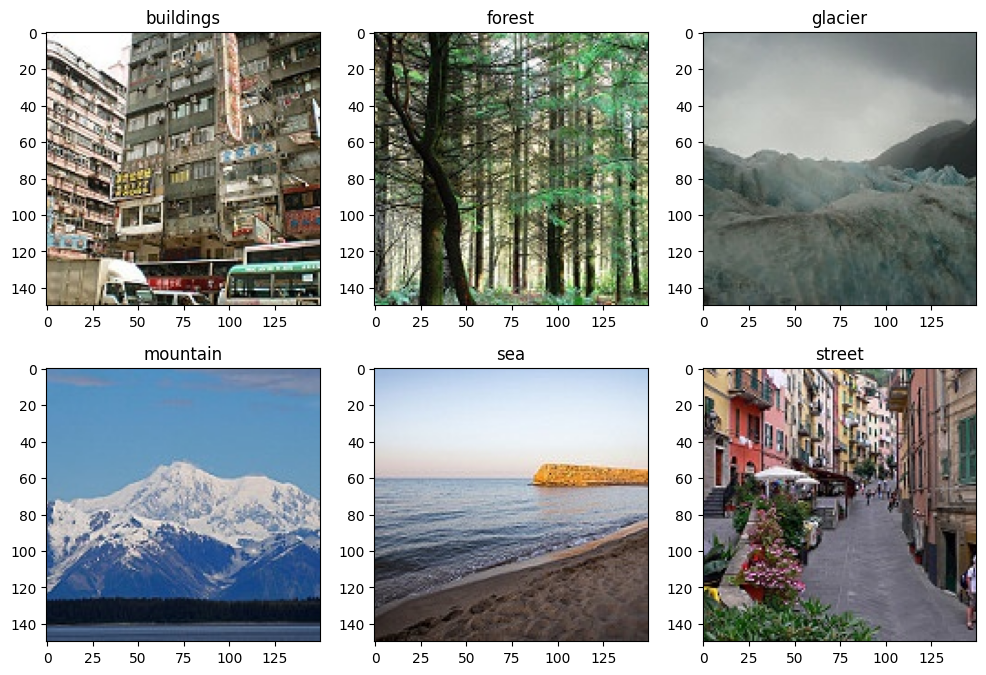

In [6]:
plt.figure(figsize=(12,8))

for i,class_name in enumerate(classes[:6]):
    class_path=os.path.join(data_dir,class_name)

    images=[
        f for f in os.listdir(class_path)
        if f.lower().endswith(image_extensions)
        and os.path.isfile(os.path.join(class_path,f))
    ]

    if not images:
        continue

    image_name=random.choice(images)
    image_path=os.path.join(class_path,image_name)

    img=Image.open(image_path).convert("RGB")

    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(class_name)

In [7]:
filepaths=[]
labels=[]

for class_name in classes:
    class_path=os.path.join(data_dir,class_name)

    for file in os.listdir(class_path):
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            filepaths.append(os.path.join(class_path,file))
            labels.append(class_name)

df=pd.DataFrame({
    'filepath':filepaths,
    'label':labels
})

train_df,temp_df=train_test_split(df,test_size=.20,random_state=42,stratify=df['label'])

val_df,test_df=train_test_split(temp_df,test_size=.50,random_state=42,stratify=temp_df['label'])

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTrain class distribution:")
print(train_df['label'].value_counts().sort_index())


Train images: 13520
Validation images: 1690
Test images: 1690

Train class distribution:
label
buildings    2087
forest       2196
glacier      2299
mountain     2422
sea          2210
street       2306
Name: count, dtype: int64
